In [36]:
import os

import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Image

sys.path.append("../src")
from surprisal import tok, lm, dev, full_surprisal, lossy_surprisal
from ns_data import load_stories

## Natural stories

Exploring ρ(d) function

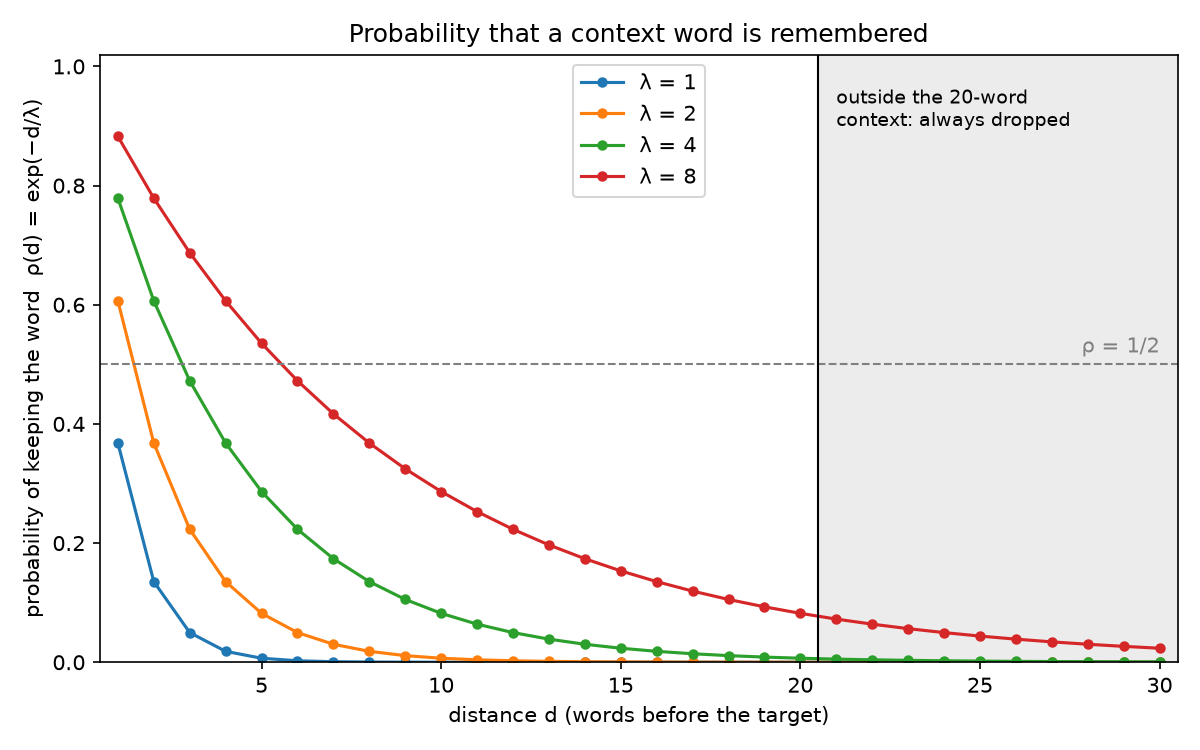

In [37]:
D = 20
d = np.arange(1, 31)

fig, ax = plt.subplots(figsize=(8, 5))
for lam in [1, 2, 4, 8]:
    ax.plot(d, np.exp(-d / lam), marker="o", markersize=4, label=f"λ = {lam}")
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.text(30, 0.52, "ρ = 1/2", ha="right", color="gray")
ax.axvline(D + 0.5, color="black", linewidth=1)
ax.axvspan(D + 0.5, d.max() + 0.5, color="gray", alpha=0.15)
ax.text(D + 1, 0.9, "outside the 20-word\ncontext: always dropped", fontsize=9)
ax.set_xlabel("distance d (words before the target)")
ax.set_ylabel("probability of keeping the word  ρ(d) = exp(−d/λ)")
ax.set_xlim(0.5, d.max() + 0.5)
ax.set_ylim(0, 1.02)
ax.set_title("Probability that a context word is remembered")
ax.legend()
plt.tight_layout()

os.makedirs("figures", exist_ok=True)
plt.savefig("figures/rho_curves.pdf")             # for the report
plt.savefig("figures/rho_curves.png", dpi=150)    # to display here
Image("figures/rho_curves.png")

In [38]:
for lam in [1, 2, 4, 8]:
    d_half = lam * np.log(2)   # solves exp(-d/lam) = 1/2
    print(f"λ = {lam}: kept with probability 1/2 at d = {d_half:.2f}")

λ = 1: kept with probability 1/2 at d = 0.69
λ = 2: kept with probability 1/2 at d = 1.39
λ = 4: kept with probability 1/2 at d = 2.77
λ = 8: kept with probability 1/2 at d = 5.55


Computing full surprisal for every word

In [39]:
stories = load_stories()
n_words = sum(len(w) for w in stories.values())
print(len(stories), "stories,", n_words, "words, device:", dev)

10 stories, 10256 words, device: cpu


In [40]:
# choosing a few words to examine

for w in ["England,", "boar's", "North", "long-bearded", "mountains."]:
    print(f"{w:15} -> {tok.tokenize(' ' + w)}")

England,        -> ['ĠEngland', ',']
boar's          -> ['Ġbo', 'ar', "'s"]
North           -> ['ĠNorth']
long-bearded    -> ['Ġlong', '-', 'be', 'arded']
mountains.      -> ['Ġmountains', '.']


In [ ]:
# check what surprisal value each token has in England,

def token_surprisals(context_words, target):
    """Surprisal (bits) of each GPT-2 token of target after context_words."""
    ctx_ids = tok.encode(" ".join(context_words)) if context_words else []
    tgt_ids = tok.encode(" " + target)
    ids = [tok.bos_token_id] + ctx_ids + tgt_ids
    with torch.no_grad():
        logp = torch.log_softmax(lm(torch.tensor([ids]).to(dev)).logits[0], dim=-1)
    first = len(ids) - len(tgt_ids)          # position of the first target token
    # the prediction for position p is made at position p - 1
    return [(tok.decode([t]), -logp[first + j - 1, t].item() / np.log(2))
            for j, t in enumerate(tgt_ids)]

s = stories[1]
i = 9                                        # s[9] = 'England,'
parts = token_surprisals(s[:i], s[i])
for token, bits in parts:
    print(f"{token!r:12} {bits:6.2f} bits")
print("sum of tokens :", round(sum(b for _, b in parts), 4))
print("full_surprisal:", round(full_surprisal(s[:i], s[i]), 4))

' England'     2.38 bits
','            2.20 bits
sum of tokens : 4.5876
full_surprisal: 4.5876


In [45]:
def surp_full_story(words):
    """Full surprisal of every word of one story (context = words before it)."""
    return [full_surprisal(words[:i], words[i]) for i in range(len(words))]

test = surp_full_story(stories[1][:20])
for w, v in zip(stories[1][:20], test):
    print(f"{w:12} {v:6.2f}")

If            13.74
you            0.81
were           5.42
to             2.09
journey       14.62
to             2.14
the            2.67
North          6.57
of             7.01
England,       4.59
you            1.61
would          1.35
come           6.17
to             3.18
a              2.64
valley         9.84
that           4.25
is             2.35
surrounded     6.98
by             0.14


In [43]:
out_dir = Path("../results/surp_full")
out_dir.mkdir(parents=True, exist_ok=True)

for story, words in stories.items():
    path = out_dir / f"story_{story}.csv"
    if path.exists():
        print(f"story {story}: already done")
        continue
    t0 = time.time()
    pd.DataFrame({"story": story,
                  "zone": range(1, len(words) + 1),   # position in the story
                  "word": words,
                  "surp_full": surp_full_story(words)}).to_csv(path, index=False)
    print(f"story {story}: {len(words)} words in {time.time() - t0:.0f} s")

surp = pd.concat([pd.read_csv(p) for p in out_dir.glob("story_*.csv")])
surp = surp.sort_values(["story", "zone"]).reset_index(drop=True)
surp.to_csv("../results/ns_surp_full.csv", index=False)

story 1: 1073 words in 532 s
story 2: 990 words in 502 s
story 3: 1040 words in 577 s
story 4: 1085 words in 751 s


KeyboardInterrupt: 

In [ ]:
assert len(surp) == n_words, "some words are missing"
assert (surp["surp_full"] > 0).all()

print(surp["surp_full"].describe().round(2))
print(surp.nsmallest(5, "surp_full")[["word", "surp_full"]])   # most predictable
print(surp.nlargest(5, "surp_full")[["word", "surp_full"]])    # most surprising
print(surp[surp["zone"] == 1][["story", "word", "surp_full"]]) # first words: empty context